# Mô hình 1: K-Means - phân cụm sản phẩm (học không giám sát)
**Mục tiêu:** chia sản phẩm Tiki + Hasaki thành các nhóm có đặc điểm giống nhau về giá, mức giảm giá,
đánh giá và số lượng bán. K-Means không cần nhãn có sẵn.

**Cột dùng:** gia_ban, gia_goc, so_tien_giam_gia, ty_le_giam_gia, diem_danh_gia_trung_binh,
so_luot_danh_gia, so_luong_da_ban.

In [2]:
# 1. Thư viện và đọc dữ liệu
import textwrap

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from common import (MODELS_DIR, load_products, prepare_ml_data, save_metrics, save_results, savefig,
                    them_cot_co_dau)
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from common import (MODELS_DIR, load_products, prepare_ml_data, save_metrics, save_results, savefig,
                    them_cot_co_dau)

FEATURES = ["Giá bán", "Giá gốc", "Số tiền giảm giá", "Tỷ lệ giảm giá",
            "Điểm đánh giá trung bình", "Số lượt đánh giá", "Số lượng đã bán"]
K_OVERRIDE = 4           # K=4: silhouette gần như phẳng từ K=3 đến K=8 (~0.30-0.32) nên chọn K=4 cho dễ diễn giải.
                         # Đặt K_OVERRIDE = None để script tự chọn K có silhouette cao nhất trong 3-8.
LABEL_OVERRIDE = {}      # muốn tự đặt tên cụm thì ghi, ví dụ {0: "Giá rẻ, bán chạy"}

raw = load_products()
print("Kích thước:", raw.shape)
print("Giá trị thiếu (trước xử lý):\n", them_cot_co_dau(raw)[FEATURES].isna().sum())

[Mongo] Kết nối thành công, database = ecommerce_db
[Dữ liệu] Đọc từ MongoDB ecommerce_db.products_cleaned: 6945 dòng
Kích thước: (6945, 17)
Giá trị thiếu (trước xử lý):
 Giá bán                       0
Giá gốc                     154
Số tiền giảm giá            154
Tỷ lệ giảm giá                0
Điểm đánh giá trung bình      0
Số lượt đánh giá              0
Số lượng đã bán             510
dtype: int64


In [3]:
# 2. Xử lý giá trị thiếu
# prepare_ml_data: rating 0 -> NaN (chưa có đánh giá), giá gốc thiếu -> bằng giá bán
df = them_cot_co_dau(prepare_ml_data(raw))
n_thieu = df[FEATURES].isna().sum()
print("\nSố ô sẽ được điền trung vị (ghi vào báo cáo):\n", n_thieu[n_thieu > 0])
print("Số dòng có ít nhất 1 ô thiếu:", int(df[FEATURES].isna().any(axis=1).sum()), "/", len(df))


Số ô sẽ được điền trung vị (ghi vào báo cáo):
 Điểm đánh giá trung bình    3016
Số lượng đã bán              510
dtype: int64
Số dòng có ít nhất 1 ô thiếu: 3029 / 6945


In [4]:
# 3. Pipeline tiền xử lý: điền trung vị -> log1p -> chuẩn hóa
# Giá và các cột đếm lệch rất mạnh nên dùng log1p; nếu bỏ bước này cụm sẽ chỉ chia theo giá.
prep = Pipeline([("impute", SimpleImputer(strategy="median")),
                 ("log", FunctionTransformer(np.log1p)),
                 ("scale", StandardScaler())])
Xs = prep.fit_transform(df[FEATURES])

      inertia  silhouette
k                        
2   35379.692       0.354
3   28370.616       0.316
4   24082.595       0.307
5   20938.041       0.312
6   17943.985       0.304
7   16266.043       0.298
8   14827.046       0.306
9   13497.851       0.300
10  12192.066       0.308
[Biểu đồ] output\figures\kmeans_chon_k.png


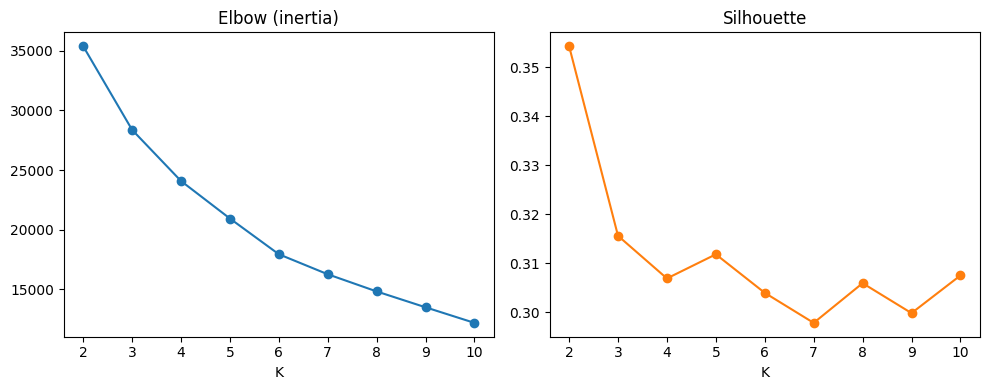

K được chọn: 4


In [5]:
# 4. Chọn K bằng elbow và silhouette (K từ 2 đến 10)
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=42).fit(Xs)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xs, km.labels_)})
ks = pd.DataFrame(rows).set_index("k")
print(ks.round(3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks.index, ks["inertia"], marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("K")
ax[1].plot(ks.index, ks["silhouette"], marker="o", color="tab:orange"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("K")
savefig(plt, "kmeans_chon_k")
plt.show()

# Chọn K có silhouette cao nhất trong khoảng 3-8 (K=2 thường quá thô để phân tích)
K = K_OVERRIDE or int(ks.loc[3:8, "silhouette"].idxmax())
print("K được chọn:", K)

In [6]:
# 5. Huấn luyện K-Means với K đã chọn
model = Pipeline([("prep", prep), ("km", KMeans(K, n_init=10, random_state=42))]).fit(df[FEATURES])
df["cluster"] = model.predict(df[FEATURES])
Z = model.named_steps["prep"].transform(df[FEATURES])
sil = float(silhouette_score(Z, df["cluster"]))
print("Silhouette:", round(sil, 3), "| Inertia:", round(model.named_steps["km"].inertia_))



Silhouette: 0.307 | Inertia: 24083


In [7]:
# 6. Bảng đặc điểm từng cụm (trung vị) và đặt tên cụm
profile = df.groupby("cluster")[FEATURES].median()
profile["Số sản phẩm"] = df.groupby("cluster").size()
# Tỷ lệ sản phẩm chưa có đánh giá trong cụm (trung vị rating chỉ tính trên sản phẩm đã có đánh giá)
profile["Tỷ lệ chưa có đánh giá (%)"] = (df["Điểm đánh giá trung bình"].isna().groupby(df["cluster"]).mean() * 100).round(1)
by_src = pd.crosstab(df["cluster"], df["nguon"])
for s in by_src.columns:
    source_name = str(s).strip().lower()
    if source_name == "hasaki":
        profile["Số sản phẩm Hasaki"] = by_src[s]
    elif source_name == "tiki":
        profile["Số sản phẩm Tiki"] = by_src[s]
    else:
        profile[f"Số sản phẩm - {s}"] = by_src[s]
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print(profile.round(2))

# Đặt tên tự động theo mức (thấp/trung bình/cao) so với toàn bộ sản phẩm; có thể sửa bằng LABEL_OVERRIDE
q = df[FEATURES].quantile([1 / 3, 2 / 3])


def muc(v, col):
    if pd.isna(v):
        return None
    return "thap" if v <= q.loc[1 / 3, col] else ("cao" if v >= q.loc[2 / 3, col] else "vua")


def dat_ten(r):
    gia = {"thap": "giá rẻ", "vua": "giá trung bình", "cao": "giá cao"}[muc(r["Giá bán"], "Giá bán")]
    ban = muc(r["Số lượng đã bán"], "Số lượng đã bán")
    ban = {"thap": "ít bán", "vua": "bán vừa", "cao": "bán chạy", None: "ít dữ liệu bán"}[ban]
    gg = "không giảm giá" if r["Tỷ lệ giảm giá"] == 0 else \
        {"thap": "giảm ít", "vua": "giảm vừa", "cao": "giảm sâu"}[muc(r["Tỷ lệ giảm giá"], "Tỷ lệ giảm giá")]
    dg = "chưa có đánh giá" if r["Số lượt đánh giá"] == 0 else \
        {"thap": "ít đánh giá", "vua": "đánh giá vừa", "cao": "nhiều đánh giá"}[muc(r["Số lượt đánh giá"], "Số lượt đánh giá")]
    return f"{gia}, {ban}, {gg}, {dg}"


labels = {int(c): dat_ten(r) for c, r in profile.iterrows()}
labels.update(LABEL_OVERRIDE)
# nếu có 2 cụm trùng tên thì thêm số cụm để phân biệt
dem = pd.Series(labels).value_counts()
labels = {c: (n if dem[n] == 1 else f"{n} (cụm {c})") for c, n in labels.items()}
for c, n in labels.items():
    print(f"Cụm {c}: {n}")
df["cluster_label"] = df["cluster"].map(labels)
profile.insert(0, "cluster_label", profile.index.map(labels))

          Giá bán   Giá gốc  Số tiền giảm giá  Tỷ lệ giảm giá  Điểm đánh giá trung bình  Số lượt đánh giá  Số lượng đã bán  Số sản phẩm  Tỷ lệ chưa có đánh giá (%)  Số sản phẩm Hasaki  \
cluster                                                                                                                                                                                   
0        163000.0  239000.0           66050.0            29.0                       4.9              40.0            210.5         1390                         0.1                 667   
1        272000.0  447000.0          149000.0            35.0                       5.0               0.0              0.0         2449                        60.9                2079   
2        250000.0  250000.0               0.0             0.0                       5.0               1.0             10.5         1885                        49.4                 143   
3         38800.0   58000.0           15000.0            28.0    

Phương sai giải thích bởi PC1, PC2: [0.294 0.287]
[Biểu đồ] output\figures\kmeans_cum_pca.png


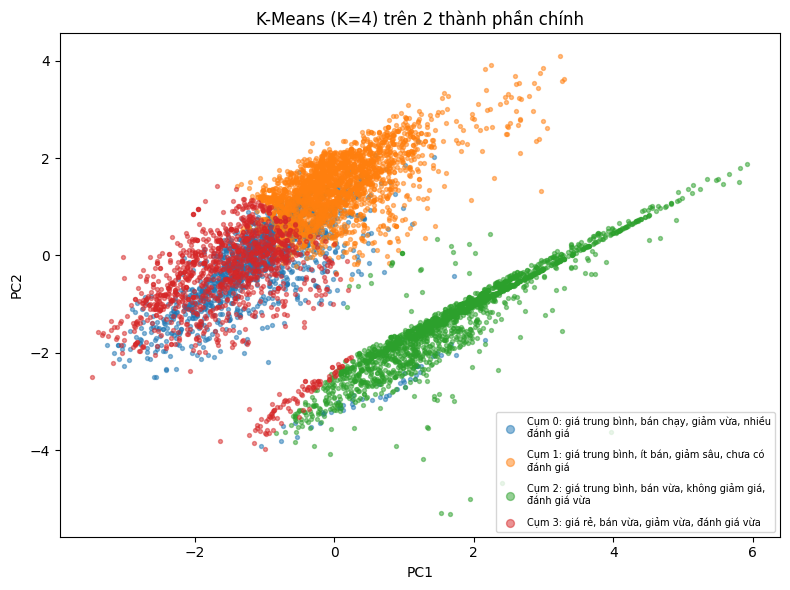

In [8]:
# 7. PCA 2 chiều để vẽ biểu đồ cụm
pca = PCA(2, random_state=42).fit(Z)
pc = pca.transform(Z)
df["pc1"], df["pc2"] = pc[:, 0].round(4), pc[:, 1].round(4)
print("Phương sai giải thích bởi PC1, PC2:", pca.explained_variance_ratio_.round(3))

plt.figure(figsize=(8, 6))
for c in sorted(labels):
    m = df["cluster"] == c
    plt.scatter(df.loc[m, "pc1"], df.loc[m, "pc2"], s=8, alpha=0.5, label=f"Cụm {c}: " + textwrap.fill(labels[c], 42))
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"K-Means (K={K}) trên 2 thành phần chính")
plt.legend(fontsize=7, markerscale=2, labelspacing=1.1)
savefig(plt, "kmeans_cum_pca")
plt.show()

In [9]:
# 8. Lưu mô hình, kết quả và chỉ số
joblib.dump({"model": model, "features": FEATURES, "labels": labels, "version": "v1"},
            MODELS_DIR / "kmeans.pkl")
save_results("ml_kmeans_results", df[["nguon", "ma_san_pham", "cluster", "cluster_label", "pc1", "pc2"]])
save_results("ml_cluster_profile", profile.reset_index())
save_metrics("kmeans",
             metrics={"silhouette": sil, "inertia": float(model.named_steps["km"].inertia_),
                      "pca_explained_variance": [float(x) for x in pca.explained_variance_ratio_],
                      "o_thieu_duoc_dien_trung_vi": {k: int(v) for k, v in n_thieu[n_thieu > 0].items()},
                      "so_san_pham_moi_cum": {str(k): int(v) for k, v in df["cluster"].value_counts().sort_index().items()}},
             params={"K": K, "features": FEATURES, "tien_xu_ly": "median impute -> log1p -> StandardScaler",
                     "n_init": 10, "random_state": 42},
             n_train=len(df))

[Lưu] ml_kmeans_results: DataFrame 6945 dòng, MongoDB 6945 document, KHỚP
[Lưu] ml_cluster_profile: DataFrame 4 dòng, MongoDB 4 document, KHỚP
[Lưu] ml_model_metrics: đã ghi kmeans


In [10]:
# KẾT THÚC: kiểm tra nhanh kết quả
print("\n=== HOÀN TẤT MÔ HÌNH 1 ===")
print("K =", K, "| Silhouette =", round(sil, 3))
print("Số sản phẩm mỗi cụm:", df["cluster"].value_counts().sort_index().to_dict())
print("Đã lưu: models/kmeans.pkl, ml_kmeans_results, ml_cluster_profile, ml_model_metrics")



=== HOÀN TẤT MÔ HÌNH 1 ===
K = 4 | Silhouette = 0.307
Số sản phẩm mỗi cụm: {0: 1390, 1: 2449, 2: 1885, 3: 1221}
Đã lưu: models/kmeans.pkl, ml_kmeans_results, ml_cluster_profile, ml_model_metrics
